---
title: "03 · Choose a model and a threshold"
---

The protocol precedes training. The notebooks inspect the shared pipeline and its saved artifacts; they do not provide a second implementation. The cached freeze is verified before any final evaluation is read.

In [1]:
from cancer_study.common import root, read_json
from IPython.display import SVG, display
import pandas as pd

project = root()
metrics_dir = project / "reports/metrics"
def figure(name):
    display(SVG(filename=str(project / "site/assets" / name)))

from cancer_study.datasets import load_development
from cancer_study.train import train, candidates
protocol = read_json(project / "protocol.json")
freeze = train(project, load_development(project))
display(pd.Series(protocol))

version                                                                          1.0
positive_class                     {'name': 'Malignant', 'value': 1, 'source_labe...
seed                                                                              42
holdout_fraction                                                                 0.2
development_folds                                                                  5
selection_metric                                                             roc_auc
practical_equivalence_auc                                                      0.005
simplicity_order                   [Logistic regression, Calibrated RBF SVM, Rand...
candidates                         {'Logistic regression': {'C': 1.0, 'max_iter':...
threshold_rule                     Maximum specificity among development out-of-f...
illustrative_sensitivity_target                                                 0.95
threshold_target_rationale         Illustrate prioritizing fewer 

## Fit preprocessing within folds

Candidates share five stratified development folds. SVM calibration wraps the entire scaler-model pipeline, so its internal validation rows do not fit the scaler. No oversampling or feature selection is used.

In [2]:
for name, estimator in candidates(protocol).items():
    print(name)
    display(estimator)

Majority baseline


,strategy,'prior'
,random_state,None
,constant,None


Logistic regression


,steps,"[('standardscaler', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


Calibrated RBF SVM


,estimator,Pipeline(step...m_state=42))])
,method,'sigmoid'
,cv,StratifiedKFo... shuffle=True)
,n_jobs,None
,ensemble,True
,copy,True
,with_mean,True
,with_std,True
,C,1.0
,kernel,'rbf'
,degree,3


Random forest


,n_estimators,300
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,3
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Compare candidates fairly

The majority baseline supplies a reference. Mean validation ROC-AUC determines ranking; the simplest candidate within 0.005 of the highest candidate mean wins. The fold SD is descriptive, not a confidence interval. The selected candidate score is optimistic after selection.

,mean,std,min,max
model,,,,
Calibrated RBF SVM,0.993498,0.009842,0.976264,0.998968
Logistic regression,0.995562,0.004105,0.989680,0.999484
Majority baseline,0.500000,0.000000,0.500000,0.500000
Random forest,0.990402,0.010233,0.975748,0.998452


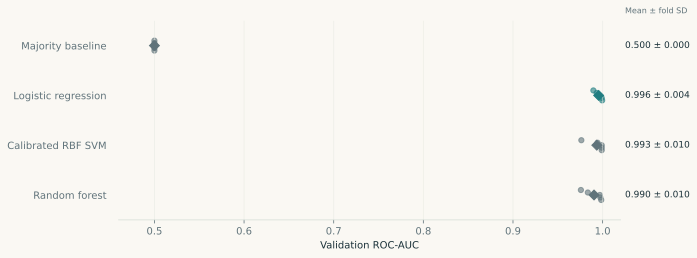

Selected: Logistic regression


In [3]:
#| fig-alt: "Five development validation-fold ROC-AUC results for a majority baseline, logistic regression, calibrated RBF SVM, and random forest."
cv = pd.read_csv(metrics_dir / "cross_validation.csv")
display(cv.groupby("model").roc_auc.agg(["mean", "std", "min", "max"]))
figure("model-comparison.svg")
print("Selected:", freeze["model"])

## Select an illustrative operating threshold

The predeclared rule maximizes specificity among development out-of-fold thresholds reaching at least 95% sensitivity. This illustrates a preference for fewer missed malignant samples, not an established clinical target. Development predictions are exploratory after selection.

In [4]:
development_result = read_json(metrics_dir / "development.json")
display(pd.Series(development_result))
print("Frozen threshold:", freeze["threshold"])
print("Frozen model SHA-256:", freeze["model_sha256"])

n                                                             455
positive_class                                      Malignant = 1
threshold                                                0.547828
tn                                                            284
fp                                                              1
fn                                                              8
tp                                                            162
accuracy                                                  0.98022
sensitivity                                              0.952941
specificity                                              0.996491
precision                                                0.993865
roc_auc                                                  0.994613
average_precision                                          0.9937
brier_score                                              0.019057
sensitivity_wilson_95    [0.9099001610494518, 0.9759644712695895]
specificit

Frozen threshold: 0.5478283925728269
Frozen model SHA-256: 4d38c1d7acd934a2ac7c0161f856b4fb08f355ed49a14054182d89945b5c947b


## Decision

Fit the chosen pipeline on all development samples and freeze its artifact and threshold. The final holdout will evaluate that fixed decision. Error inspection after the holdout does not trigger model revision.